# NumPy로 구현한 GPT-2

GPT-2 small(124M)을 NumPy 행렬 연산만으로 구현하고, 공개 가중치를 올려 Hugging Face 구현과 같은 logits가 나오는지 확인하는 노트북이다. Hugging Face에서는 가중치(`model.safetensors`)와 토크나이저 파일(`vocab.json`, `merges.txt`)만 받고, BPE 토크나이저와 순전파·샘플링은 아래 셀에서 직접 계산한다. `transformers`와 `tiktoken`은 정답 확인용으로만 쓴다.

설명과 실험 결과 해석은 블로그 글 [NumPy로 구현한 GPT-2](https://wtcyj.github.io/posts/gpt2-numpy-from-scratch/)에 있다.

In [1]:
%pip install -q tiktoken transformers safetensors regex

In [2]:
import json
import numpy as np
import regex
import matplotlib.pyplot as plt
from huggingface_hub import hf_hub_download
from safetensors.numpy import load_file

REPO = "gpt2"
NH = 12  # 헤드 수

## 1. 토크나이저: 바이트 단위 BPE

문장을 UTF-8 바이트로 바꾸고, `merges.txt`에 적힌 순서대로 붙어 있는 두 조각을 합쳐 나간다.

In [3]:
def b2u_table():
    # 바이트 0~255 -> 눈에 보이는 글자 256개로 1:1 매핑함 (gpt2 원본이랑 같은 표임)
    bs = list(range(ord("!"), ord("~") + 1)) + list(range(ord("¡"), ord("¬") + 1)) + list(range(ord("®"), ord("ÿ") + 1))
    cs = bs[:]
    n = 0
    for b in range(256):
        if b not in bs:
            bs.append(b)
            cs.append(256 + n)
            n += 1
    return dict(zip(bs, map(chr, cs)))


class BPE:
    # 먼저 단어 단위로 자름: 축약형 / 공백+글자 / 공백+숫자 / 공백+기호 / 공백
    PAT = regex.compile(r"""'s|'t|'re|'ve|'m|'ll|'d| ?\p{L}+| ?\p{N}+| ?[^\s\p{L}\p{N}]+|\s+(?!\S)|\s+""")

    def __init__(self):
        self.enc = json.load(open(hf_hub_download(REPO, "vocab.json"), encoding="utf-8"))
        self.dec = {v: k for k, v in self.enc.items()}
        ms = open(hf_hub_download(REPO, "merges.txt"), encoding="utf-8").read().split("\n")[1:-1]
        self.rank = {tuple(m.split()): i for i, m in enumerate(ms)}  # 위에 있을수록 먼저 합침
        self.b2u = b2u_table()
        self.u2b = {v: k for k, v in self.b2u.items()}

    def bpe(self, w, tr=None):
        # 한 글자씩 쪼갠 다음 rank 제일 낮은 쌍부터 계속 합침
        p = list(w)
        while len(p) > 1:
            r, i = min((self.rank.get(x, 1e18), i) for i, x in enumerate(zip(p, p[1:])))
            if r == 1e18:  # 더 합칠 쌍 없음
                break
            a, b = p[i], p[i + 1]
            out, j = [], 0
            while j < len(p):  # 같은 쌍 여러 개면 왼쪽부터 다 합침
                if j < len(p) - 1 and p[j] == a and p[j + 1] == b:
                    out.append(a + b)
                    j += 2
                else:
                    out.append(p[j])
                    j += 1
            p = out
            if tr is not None:
                tr.append((int(r), (a, b), p[:]))
        return p

    def encode(self, s):
        ids = []
        for x in self.PAT.findall(s):
            w = "".join(self.b2u[b] for b in x.encode("utf-8"))
            ids += [self.enc[t] for t in self.bpe(w)]
        return ids

    def decode(self, ids):
        bs = bytes(self.u2b[c] for c in "".join(self.dec[i] for i in ids))
        return bs.decode("utf-8", errors="replace")

    def tbytes(self, i):
        return bytes(self.u2b[c] for c in self.dec[i])


In [4]:
tok = BPE()

# 병합 과정 찍어봄 (앞에 공백 붙은 tokenization)
tr = []
tok.bpe(''.join(tok.b2u[b] for b in ' tokenization'.encode()), tr)
for r, (a, b), p in tr:
    print(f'{r:>6}  {a!r:>8} + {b!r:<8} -> {" ".join(p)}')

     0       'Ġ' + 't'      -> Ġt o k e n i z a t i o n
     5       'o' + 'n'      -> Ġt o k e n i z a t i on
     9       'a' + 't'      -> Ġt o k e n i z at i on
    12       'e' + 'n'      -> Ġt o k en i z at i on
    28      'Ġt' + 'o'      -> Ġto k en i z at i on
    39       'i' + 'on'     -> Ġto k en i z at ion
    85      'at' + 'ion'    -> Ġto k en i z ation
   272       'i' + 'z'      -> Ġto k en iz ation
  1378      'iz' + 'ation'  -> Ġto k en ization
  3208       'k' + 'en'     -> Ġto ken ization
 10985     'Ġto' + 'ken'    -> Ġtoken ization


In [5]:
import tiktoken
tt = tiktoken.get_encoding('gpt2')

# tiktoken이랑 토큰 id 같은지 확인
for s in ['Hello, world!', "I've been waiting for 1,234,567 years...", '안녕하세요. 오늘 날씨가 정말 좋네요!', 'emoji 🤖 and ünïcödé']:
    ids = tok.encode(s)
    assert ids == tt.encode(s) and tok.decode(ids) == s
    print(len(ids), 'tokens, same as tiktoken:', s)

print('안녕하세요 ->', [tok.tbytes(i).hex(' ') for i in tok.encode('안녕하세요')])

4 tokens, same as tiktoken: Hello, world!
13 tokens, same as tiktoken: I've been waiting for 1,234,567 years...
46 tokens, same as tiktoken: 안녕하세요. 오늘 날씨가 정말 좋네요!
14 tokens, same as tiktoken: emoji 🤖 and ünïcödé
안녕하세요 -> ['ec', '95', '88', 'eb', '85', '95', 'ed 95', '98', 'ec', '84', 'b8', 'ec', '9a', '94']


## 2. 가중치 불러오기

Hugging Face GPT-2는 `Conv1D`를 써서 가중치가 (입력, 출력) 모양으로 저장돼 있다. 그래서 `x @ W`로 바로 곱한다.

In [6]:
w = load_file(hf_hub_download(REPO, 'model.safetensors'))
print(len(w), 'tensors,', sum(v.size for k, v in w.items() if not k.endswith('attn.bias')), 'params')
for k in ['wte.weight', 'wpe.weight', 'h.0.attn.c_attn.weight', 'h.0.attn.c_proj.weight', 'h.0.mlp.c_fc.weight']:
    print(f'{k:<26}', w[k].shape)

160 tensors, 124412160 params
wte.weight                 (50257, 768)
wpe.weight                 (1024, 768)
h.0.attn.c_attn.weight     (768, 2304)
h.0.attn.c_proj.weight     (768, 768)
h.0.mlp.c_fc.weight        (768, 3072)


## 3. 부품: LayerNorm, GELU, softmax, self-attention, MLP

`attn`의 `causal`, `scale` 인자와 `fwd`의 `res` 인자는 뒤의 실험에서 그 장치를 끄려고 넣은 것이다. 기본값이 GPT-2와 같은 동작이다.

In [7]:
def ln(x, g, b, eps=1e-5):
    mu = x.mean(-1, keepdims=True)
    var = x.var(-1, keepdims=True)  # n으로 나누는 분산임 (torch LayerNorm이랑 같음)
    return (x - mu) / np.sqrt(var + eps) * g + b


def gelu(x):
    # gpt2는 tanh 근사식(gelu_new) 씀
    return 0.5 * x * (1 + np.tanh(np.sqrt(2 / np.pi) * (x + 0.044715 * x**3)))


def softmax(x, ax=-1):
    x = x - x.max(ax, keepdims=True)  # exp 터지는 거 막음
    e = np.exp(x)
    return e / e.sum(ax, keepdims=True)


In [8]:
def attn(x, w, p, causal=True, scale=True, keep=None):
    T, C = x.shape
    d = C // NH  # 64
    qkv = x @ w[p + "c_attn.weight"] + w[p + "c_attn.bias"]  # (T, 3C)
    q, k, v = np.split(qkv, 3, axis=-1)
    q, k, v = (a.reshape(T, NH, d).transpose(1, 0, 2) for a in (q, k, v))  # (H, T, d)
    s = q @ k.transpose(0, 2, 1)  # (H, T, T)
    if scale:
        s = s / np.sqrt(d)
    if causal:
        fut = np.triu(np.ones((T, T), dtype=bool), k=1)  # j > i 칸 = 미래
        s = np.where(fut, -1e10, s)
    a = softmax(s)
    if keep is not None:
        keep.append(dict(q=q, k=k, att=a))
    o = (a @ v).transpose(1, 0, 2).reshape(T, C)  # 헤드 다시 이어붙임
    return o @ w[p + "c_proj.weight"] + w[p + "c_proj.bias"]


In [9]:
def mlp(x, w, p):
    h = gelu(x @ w[p + "c_fc.weight"] + w[p + "c_fc.bias"])  # 768 -> 3072
    return h @ w[p + "c_proj.weight"] + w[p + "c_proj.bias"]  # 3072 -> 768


def fwd(ids, w, causal=True, scale=True, res=True, keep=None):
    # ids -> logits (T, 50257). causal/scale/res 끄면 그 장치 뺀 모델 됨 (실험용)
    ids = np.asarray(ids)
    x = w["wte.weight"][ids] + w["wpe.weight"][np.arange(len(ids))]  # 토큰 임베딩 + 위치 임베딩
    for i in range(12):
        p = f"h.{i}."
        a = attn(ln(x, w[p + "ln_1.weight"], w[p + "ln_1.bias"]), w, p + "attn.", causal, scale, keep)
        x = x + a if res else a
        m = mlp(ln(x, w[p + "ln_2.weight"], w[p + "ln_2.bias"]), w, p + "mlp.")
        x = x + m if res else m
    x = ln(x, w["ln_f.weight"], w["ln_f.bias"])
    return x @ w["wte.weight"].T  # 출력층 따로 없음. 입력 임베딩 재사용함 (weight tying)


## 4. Hugging Face와 logits 비교

같은 토큰을 넣고 모든 위치의 logits(토큰 수 × 50,257)를 비교한다. float32 오차가 반올림 때문인지 보려고 양쪽을 float64로 올려 한 번 더 잰다.

In [10]:
import torch
from transformers import GPT2LMHeadModel

hf = GPT2LMHeadModel.from_pretrained('gpt2', attn_implementation='eager').eval()
ps = ['Hello, my name is', 'The capital of France is', '안녕하세요. 오늘 날씨가']
for p in ps:
    ids = tok.encode(p)
    me = fwd(ids, w)
    with torch.no_grad():
        ref = hf(torch.tensor([ids])).logits[0].numpy()
    print(f'{p!r:<30} tokens={len(ids):>2}  max|diff|={np.abs(me - ref).max():.2e}  '
          f'argmax same={(me.argmax(-1) == ref.argmax(-1)).all()}')

'Hello, my name is'            tokens= 5  max|diff|=1.42e-04  argmax same=True


'The capital of France is'     tokens= 5  max|diff|=1.21e-04  argmax same=True


'안녕하세요. 오늘 날씨가'                tokens=30  max|diff|=9.18e-05  argmax same=True


In [11]:
# 둘 다 float64로 올려서 다시 잼
w64 = {k: v.astype(np.float64) for k, v in w.items()}
hf64 = GPT2LMHeadModel.from_pretrained('gpt2', attn_implementation='eager', torch_dtype=torch.float64).eval()
for p in ps:
    ids = tok.encode(p)
    with torch.no_grad():
        ref = hf64(torch.tensor([ids])).logits[0].numpy()
    print(f'float64 {p!r:<30} max|diff|={np.abs(fwd(ids, w64) - ref).max():.2e}')

float64 'Hello, my name is'            max|diff|=4.41e-13


float64 'The capital of France is'     max|diff|=6.61e-13


float64 '안녕하세요. 오늘 날씨가'                max|diff|=5.40e-13


## 5. 생성과 샘플링

In [12]:
def sample(lg, rng, t=1.0, k=None, p=None):
    if t == 0:  # greedy
        return int(np.argmax(lg))
    z = lg / t
    if k is not None:  # 상위 k개만 남김
        kth = np.sort(z)[-k]
        z = np.where(z < kth, -np.inf, z)
    pr = softmax(z)
    if p is not None:  # 누적확률 p 넘은 다음 토큰부터 버림
        o = np.argsort(-pr)
        cum = np.cumsum(pr[o])
        pr[o[cum - pr[o] >= p]] = 0
        pr /= pr.sum()
    return int(rng.choice(len(pr), p=pr))


def gen(ids, w, n, seed=0, **kw):
    # kv캐시 없이 매번 전체 다시 계산함. 50토큰 정도면 충분히 빠름
    rng = np.random.default_rng(seed)
    ids = list(ids)
    for _ in range(n):
        t = sample(fwd(ids, w)[-1], rng, **kw)
        ids.append(t)
        if t == 50256:  # <|endoftext|>
            break
    return ids


In [13]:
ids = tok.encode('Alan Turing theorized that computers would one day become')
me = gen(ids, w, 20, t=0)
with torch.no_grad():
    ref = hf.generate(torch.tensor([ids]), max_new_tokens=20, do_sample=False, pad_token_id=50256)[0].tolist()
print(tok.decode(me))
print('same as HF greedy:', me == ref[:len(me)])

Alan Turing theorized that computers would one day become the most powerful machines on the planet.

The computer is a machine that can perform complex calculations
same as HF greedy: True


In [14]:
pr = tok.encode('Once upon a time, in a small village by the sea,')
for nm, kw in [('greedy', dict(t=0)), ('T=0.1', dict(t=0.1)), ('T=1.0', dict(t=1.0)), ('T=2.0', dict(t=2.0)),
               ('top-k=40', dict(t=1.0, k=40)), ('top-p=0.9', dict(t=1.0, p=0.9))]:
    o = gen(pr, w, 25, seed=0, **kw)
    print(f'{nm:<9}', repr(tok.decode(o[len(pr):])))

greedy    ' a man named Tzal, who had been a member of the royal family, had been sent to the city of T'


T=0.1     ' a man named Tzitza was a young man, and he was a man of great wealth. He was a man'


T=1.0     ' no one for a hundred miles got away and scattered those a sleeping-bird-eye from the tree, and those four alone'


T=2.0     " drilling paper's on liquidity tweaked ma solicitalogcomponent envisioned, extravagaccomplish ordained scholar Ma Oceanis met Princeton linguaki"


top-k=40  " as the first-born son of the king's royal-daughter, his mother saw this world in a way that she never"


top-p=0.9 ' there was a jaguar game which could draw almost a thousand of its own birds. The players, with one bird or'


## 6. 어텐션 맵

`keep` 리스트에 각 층의 어텐션 행렬을 모아 그린다. 층 4 헤드 11은 바로 앞 토큰만 보고, 층 4 헤드 3은 `it`에서 `animal`을 강하게 본다.

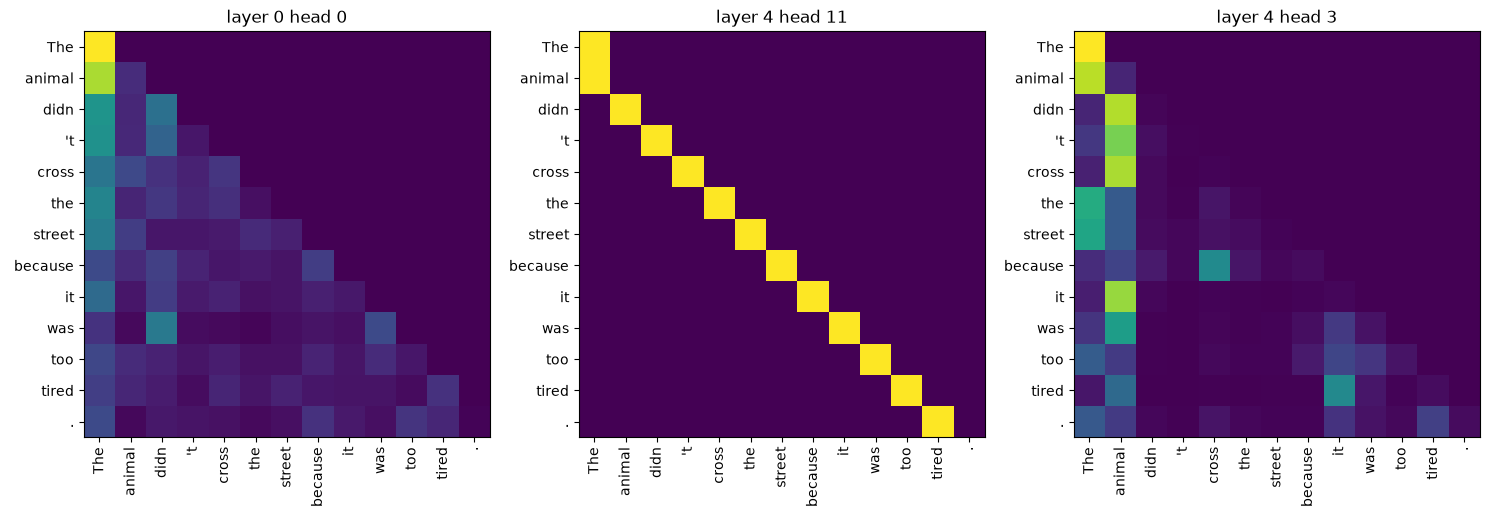

In [15]:
sent = "The animal didn't cross the street because it was too tired."
ids = tok.encode(sent)
lab = [tok.decode([i]) for i in ids]
keep = []
fwd(ids, w, keep=keep)
att = np.stack([k['att'] for k in keep])  # (층, 헤드, T, T)

fig, axs = plt.subplots(1, 3, figsize=(15, 5))
for ax, (l, h) in zip(axs, [(0, 0), (4, 11), (4, 3)]):
    ax.imshow(att[l, h], vmin=0, vmax=1)
    ax.set_xticks(range(len(lab)), lab, rotation=90)
    ax.set_yticks(range(len(lab)), lab)
    ax.set_title(f'layer {l} head {h}')
plt.tight_layout()
plt.show()

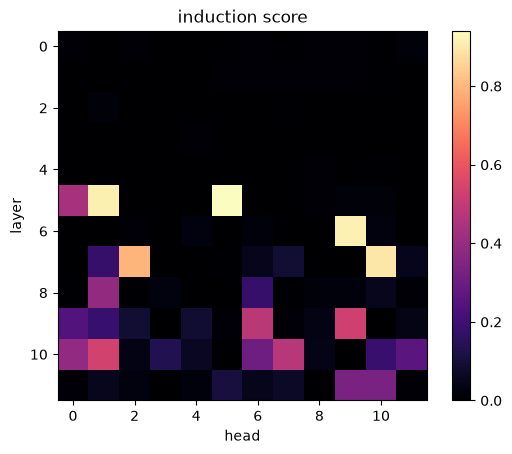

top heads: ['5.5 0.94', '6.9 0.92', '5.1 0.91', '7.10 0.89', '7.2 0.80']


In [16]:
# induction head: 랜덤 토큰 50개 두 번 반복해서 넣고 '지난번 다음 토큰' 보는 정도 헤드별로 잼
rng = np.random.default_rng(0)
seq = rng.integers(1000, 20000, 50).tolist()
ids = [50256] + seq + seq
keep = []
fwd(ids, w, keep=keep)
att = np.stack([k['att'] for k in keep])
q = np.arange(51, 101)  # 두 번째 반복 구간
sc = att[:, :, q, q - 49].mean(-1)

plt.imshow(sc, cmap='magma')
plt.xlabel('head'); plt.ylabel('layer'); plt.colorbar()
plt.title('induction score')
plt.show()
print('top heads:', [f'{a}.{b} {sc[a, b]:.2f}' for a, b in zip(*np.unravel_index(np.argsort(-sc, axis=None)[:5], (12, 12)))])

## 7. 부품을 빼 보기: √d_k, causal mask, 잔차 연결

같은 문단의 토큰당 손실(다음 토큰 cross-entropy)을 장치 하나씩 끄고 다시 잰다.

In [17]:
text = ('Alice was beginning to get very tired of sitting by her sister on the bank, and of having '
        'nothing to do: once or twice she had peeped into the book her sister was reading, but it had '
        'no pictures or conversations in it.')
ids = np.array(tok.encode(text))

def loss(**kw):  # 토큰당 다음 토큰 ce
    lg = fwd(ids, w, **kw)[:-1]
    lg = lg - lg.max(-1, keepdims=True)
    lp = lg - np.log(np.exp(lg).sum(-1, keepdims=True))
    return -lp[np.arange(len(ids) - 1), ids[1:]].mean()

print(f'gpt2 그대로         {loss():.2f}')
print(f'√d_k로 안 나눔       {loss(scale=False):.2f}')
print(f'causal mask 뺌      {loss(causal=False):.2f}')
print(f'잔차 연결 뺌         {loss(res=False):.2f}')
print(f'균등분포(참고)       {np.log(50257):.2f}')

gpt2 그대로         3.33


√d_k로 안 나눔       5.78


causal mask 뺌      4.43


잔차 연결 뺌         9.23
균등분포(참고)       10.82


결과 해석과 나머지 실험(한국어 토큰 수, temperature 분포, SFT·DPO·GRPO 손실, 2026년 모델 비교)은 [블로그 글](https://wtcyj.github.io/posts/gpt2-numpy-from-scratch/)에 정리했다.